In [ ]:
import tensorflow as tf
import numpy as np

In [ ]:
path = tf.keras.utils.get_file(
    "shakespeare.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt"
)

text = open(path, "r", encoding="utf-8").read()

print("Total characters:", len(text))
print(text[:300])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total characters: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [ ]:
chars = sorted(set(text))
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = np.array(chars)

encoded_text = np.array([char_to_idx[c] for c in text])

print("Vocabulary size:", len(chars))
print("Encoded text:", encoded_text[:20])

Vocabulary size: 65
Encoded text: [18 47 56 57 58  1 15 47 58 47 64 43 52 10  0 14 43 44 53 56]


In [ ]:
SEQ_LEN = 100
STEP = 3

X = []
y = []

for i in range(0, len(encoded_text) - SEQ_LEN, STEP):
    X.append(encoded_text[i:i + SEQ_LEN])
    y.append(encoded_text[i + SEQ_LEN])

X = np.array(X)
y = np.array(y)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (371765, 100)
Target shape: (371765,)


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQ_LEN,)),
    tf.keras.layers.Embedding(len(chars), 64),
    tf.keras.layers.LSTM(128),
    tf.keras.layers.Dense(len(chars), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 65)             │         8,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,361 (435.00 KB)

 Trainable params: 111,361 (435.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X, y,
    batch_size=128,
    epochs=5,
    validation_split=0.1
)

Epoch 1/5
2614/2614 ━━━━━━━━━━━━━━━━━━━━ 31s 10ms/step - accuracy: 0.3497 - loss: 2.2877 - val_accuracy: 0.3924 - val_loss: 2.0596
Epoch 2/5
2614/2614 ━━━━━━━━━━━━━━━━━━━━ 36s 10ms/step - accuracy: 0.4432 - loss: 1.8999 - val_accuracy: 0.4333 - val_loss: 1.9132
Epoch 3/5
2614/2614 ━━━━━━━━━━━━━━━━━━━━ 26s 10ms/step - accuracy: 0.4797 - loss: 1.7636 - val_accuracy: 0.4589 - val_loss: 1.8431
Epoch 4/5
2614/2614 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.4995 - loss: 1.6872 - val_accuracy: 0.4705 - val_loss: 1.7943
Epoch 5/5
2614/2614 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.5128 - loss: 1.6350 - val_accuracy: 0.4827 - val_loss: 1.7678


In [ ]:
def generate_text(seed, length=300, temperature=0.8):
    seed = seed[-SEQ_LEN:].rjust(SEQ_LEN)
    generated = seed

    for _ in range(length):
        seq = np.array([[char_to_idx.get(c, char_to_idx[" "])
                         for c in seed]])

        predictions = model(seq, training=False).numpy()[0]
        predictions = np.log(predictions + 1e-8) / temperature
        predictions = np.exp(predictions - np.max(predictions))
        predictions /= predictions.sum()

        next_id = np.random.choice(len(chars), p=predictions)
        next_char = idx_to_char[next_id]

        generated += next_char
        seed = seed[1:] + next_char

    return generated

In [ ]:
print(generate_text("ROMEO:", length=300, temperature=0.8))

                                                                                              ROMEO:
Hat, gook upon this geince trief, sence befile,
If her verisices we hought of heart'd, so,
A shie well; was speak the heavenys to know my love
We did a took will know the werlion, with as the tless:
Marcies in liee, pear thou could preath, to pead in
the offend.
Good good the fall to my so. Which d


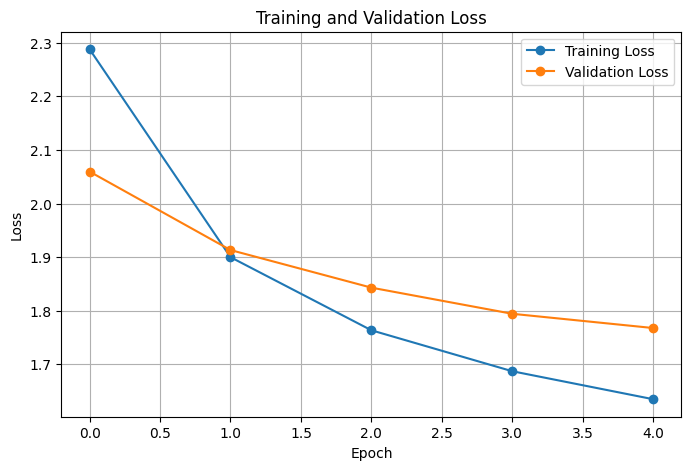

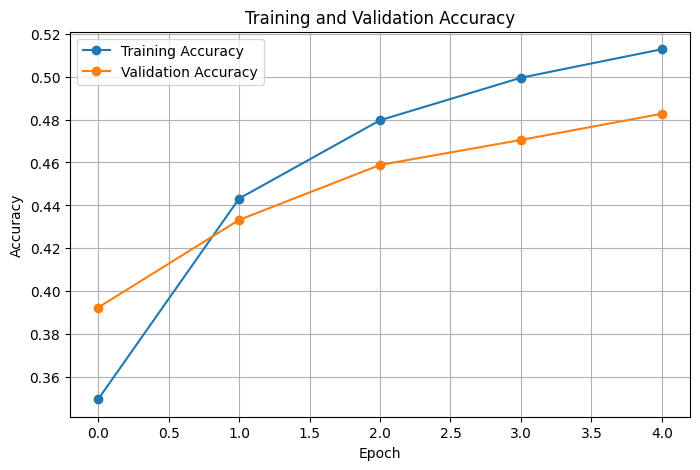

In [ ]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()